In [1]:
#Import required libraries
import os
import numpy as np 
from pathlib import Path
from sklearn.datasets import load_breast_cancer
import sys
from pathlib import Path
import joblib
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import preprocessing tools
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


Dataset Loading – Breast Cancer Wisconsin (Diagnostic)

In [2]:


# Load the Breast Cancer Wisconsin dataset

breast_cancer = load_breast_cancer(as_frame=True)

# Extract the input features
X = breast_cancer.data.copy()

# Extract the target variable
y = breast_cancer.target.copy()

# Convert target values into meaningful labels
# 0 = Malignant (M)
# 1 = Benign (B)
y = y.map({
    0: "M",
    1: "B"
})

# Combine features and target into one DataFrame
df = X.copy()
df["diagnosis"] = y


# the project root directory
project_root = Path.cwd()

# If the notebook is running from the notebooks folder,
# move one level up to the project root
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

# Add project root to Python import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Define the dataset output directory
dataset_folder = project_root / "dataset"

# Create the folder if it does not exist
dataset_folder.mkdir(parents=True, exist_ok=True)

# Save the dataset as a CSV file

dataset_path = dataset_folder / "breast_cancer.csv"

df.to_csv(dataset_path, index=False)

print("Dataset successfully loaded and saved.")
print("Dataset location:", dataset_path)

Dataset successfully loaded and saved.
Dataset location: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\dataset\breast_cancer.csv


# 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset,
identify patterns, examine feature distributions, and check
relationships between the input features and the target variable.

## 2.1 Dataset Overview

In [3]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (569, 31)

Column names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-n

## 2.2 Missing Values and Duplicate Records

In [4]:
# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nTotal duplicate records:", df.duplicated().sum())

Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

Total missing values: 0

Total duplicate records: 0


## 2.3 Target Variable Distribution

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis percentages:
diagnosis
B    62.74
M    37.26
Name: count, dtype: float64


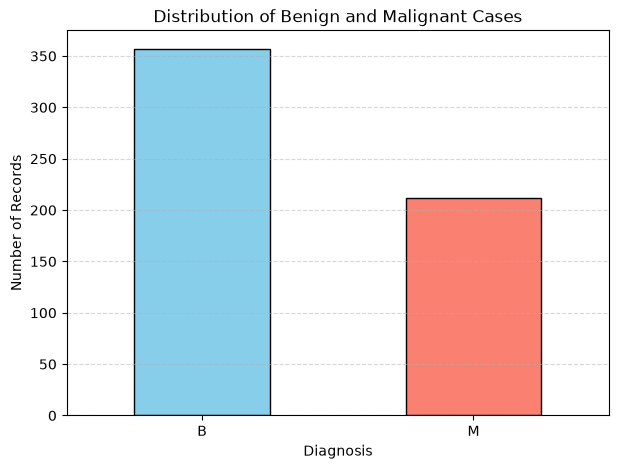

In [5]:
# Count the number of records in each diagnosis category
target_counts = df["diagnosis"].value_counts()

# Display counts and percentages
print("Diagnosis counts:")
print(target_counts)

print("\nDiagnosis percentages:")
print((target_counts / len(df) * 100).round(2))

# Plot the class distribution
plt.figure(figsize=(7, 5))

target_counts.plot(
    kind="bar",
    color=["skyblue", "salmon"],
    edgecolor="black"
)

plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

Observation – Target Variable Distribution

The dataset contains 569 observations, consisting of 357 benign cases (62.74%) and 212 malignant cases (37.26%). The target variable exhibits moderate class imbalance, with benign cases forming the majority class. Therefore, stratified train-test splitting will be used to preserve class proportions, and multiple evaluation metrics will be considered rather than relying exclusively on accuracy.

## 2.4 Descriptive Statistics

In [6]:
# Calculate descriptive statistics for numerical features
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## 2.5 Feature Distributions

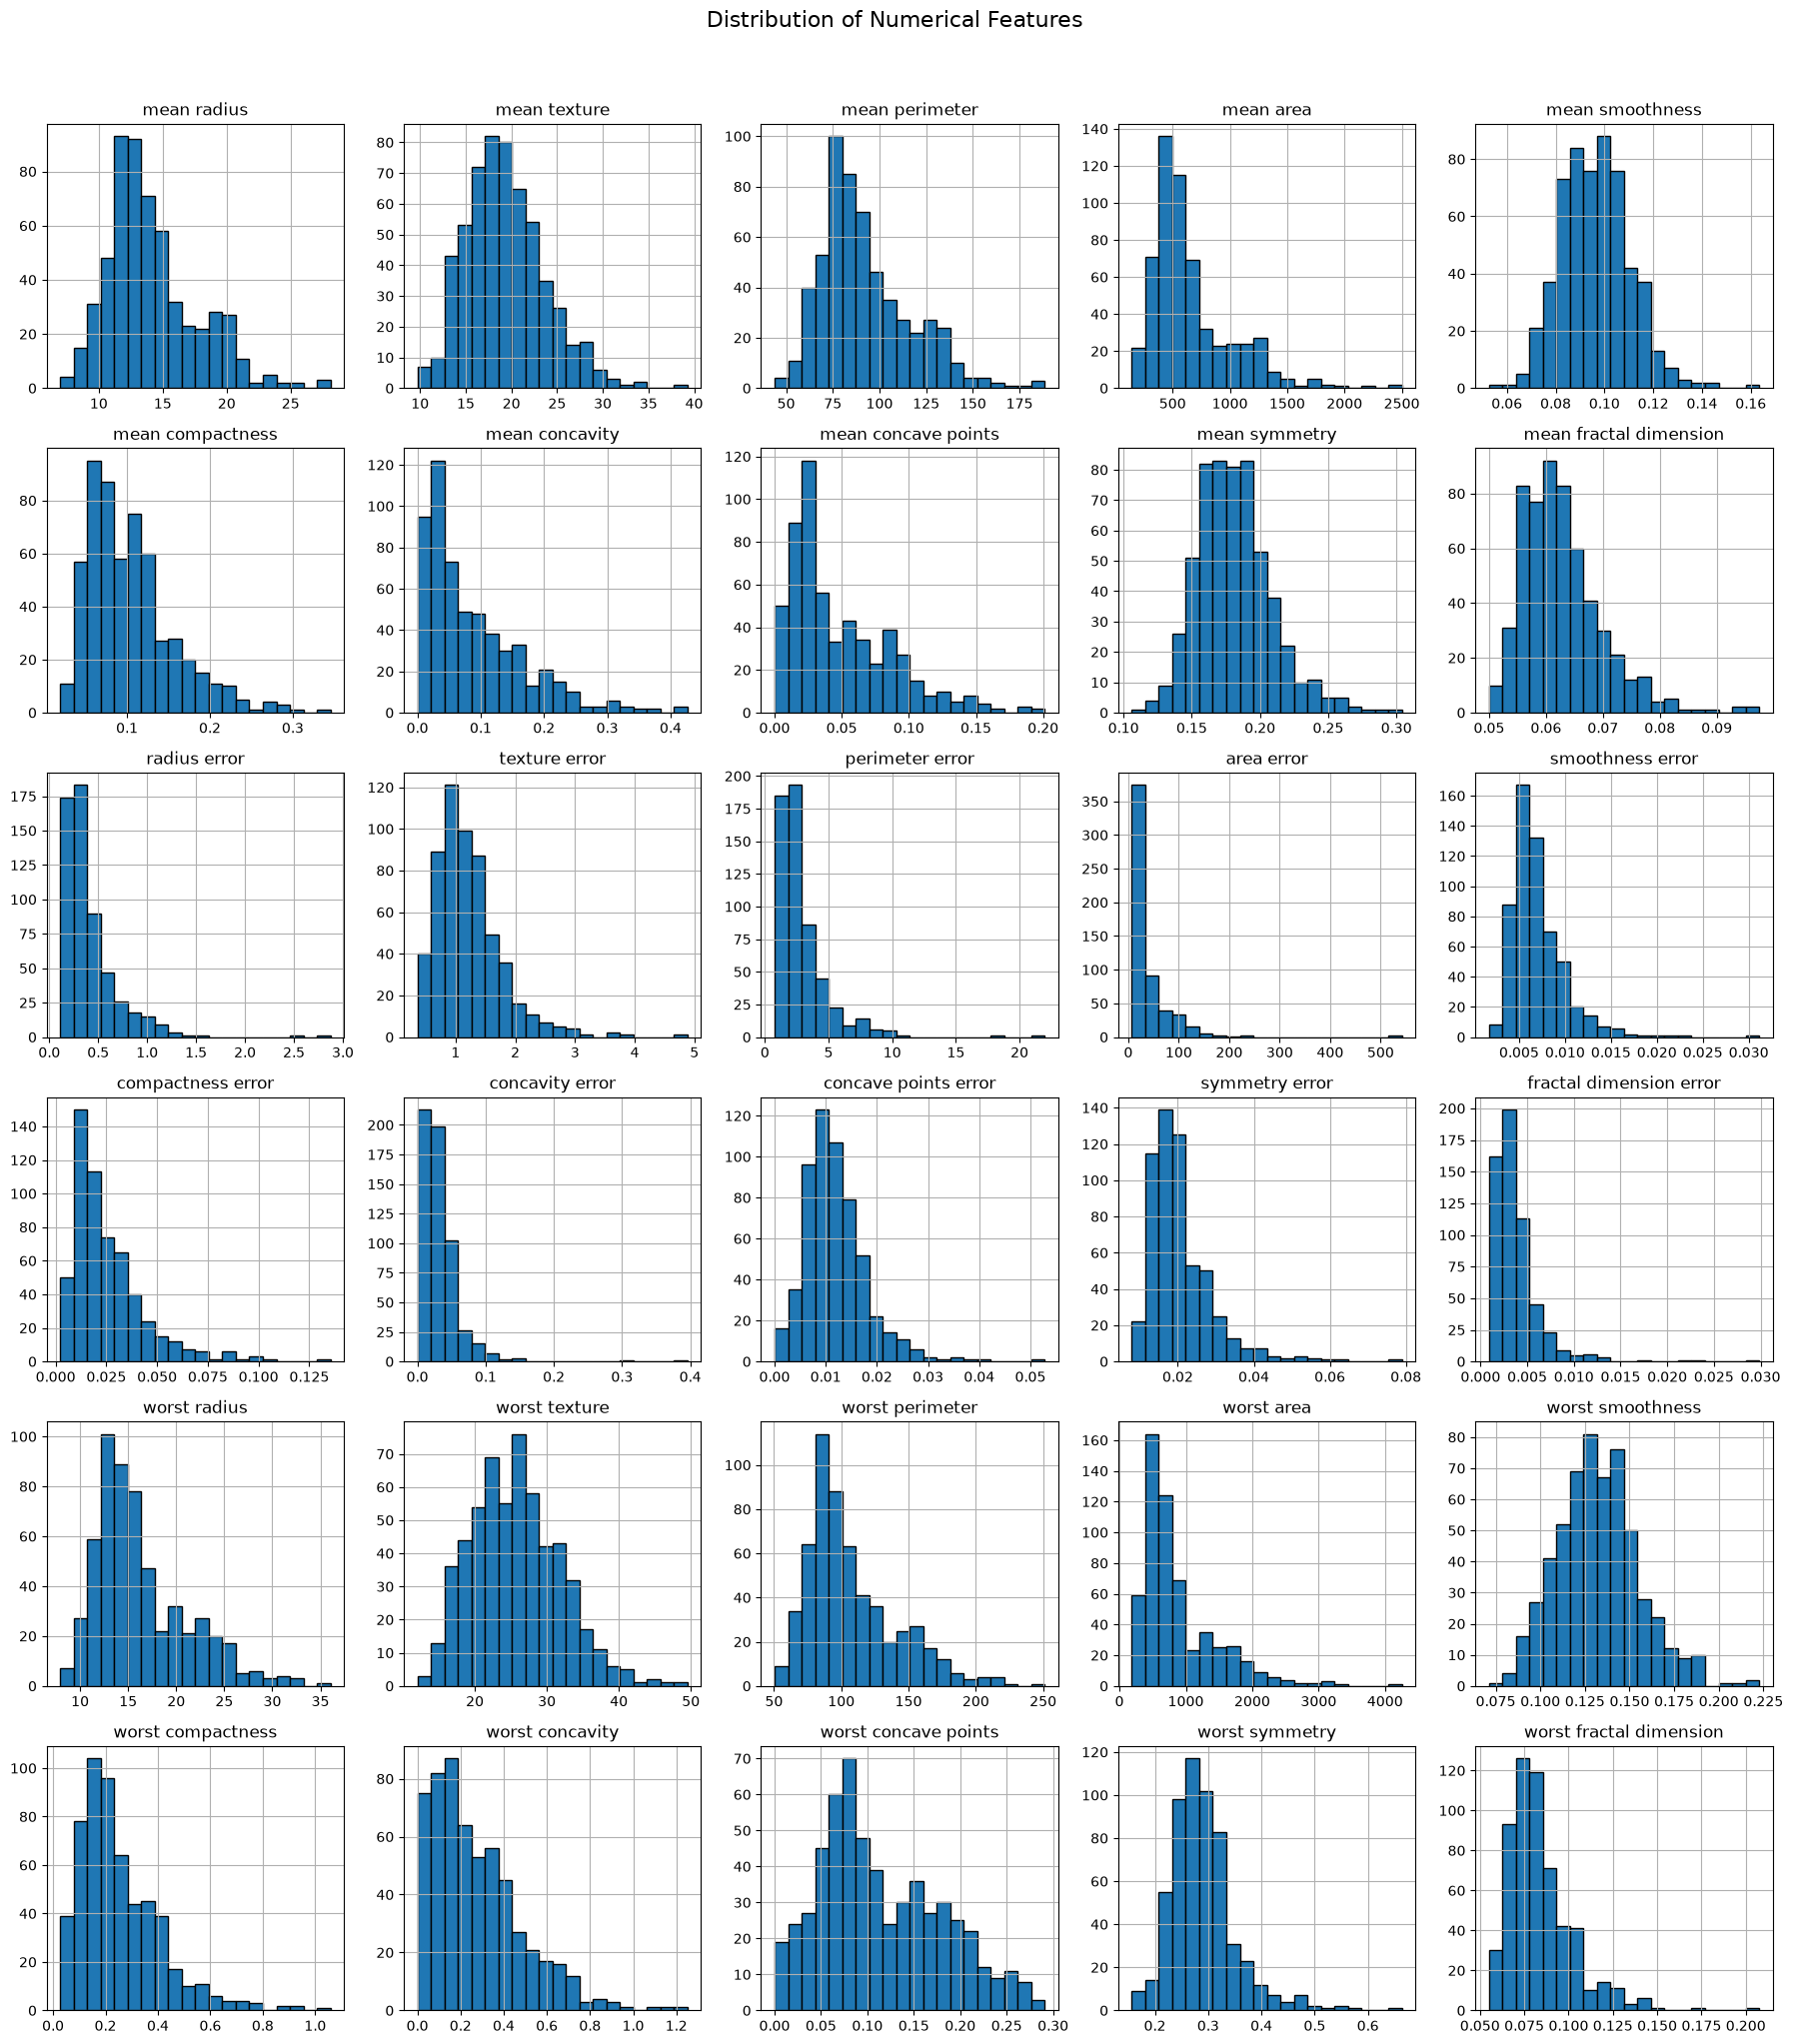

In [7]:
# Select all input features, excluding the target variable
features = df.drop(columns=["diagnosis"])

# Plot histograms for all 30 features
features.hist(
    figsize=(18, 20),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

## 2.6 Feature Correlation Analysis

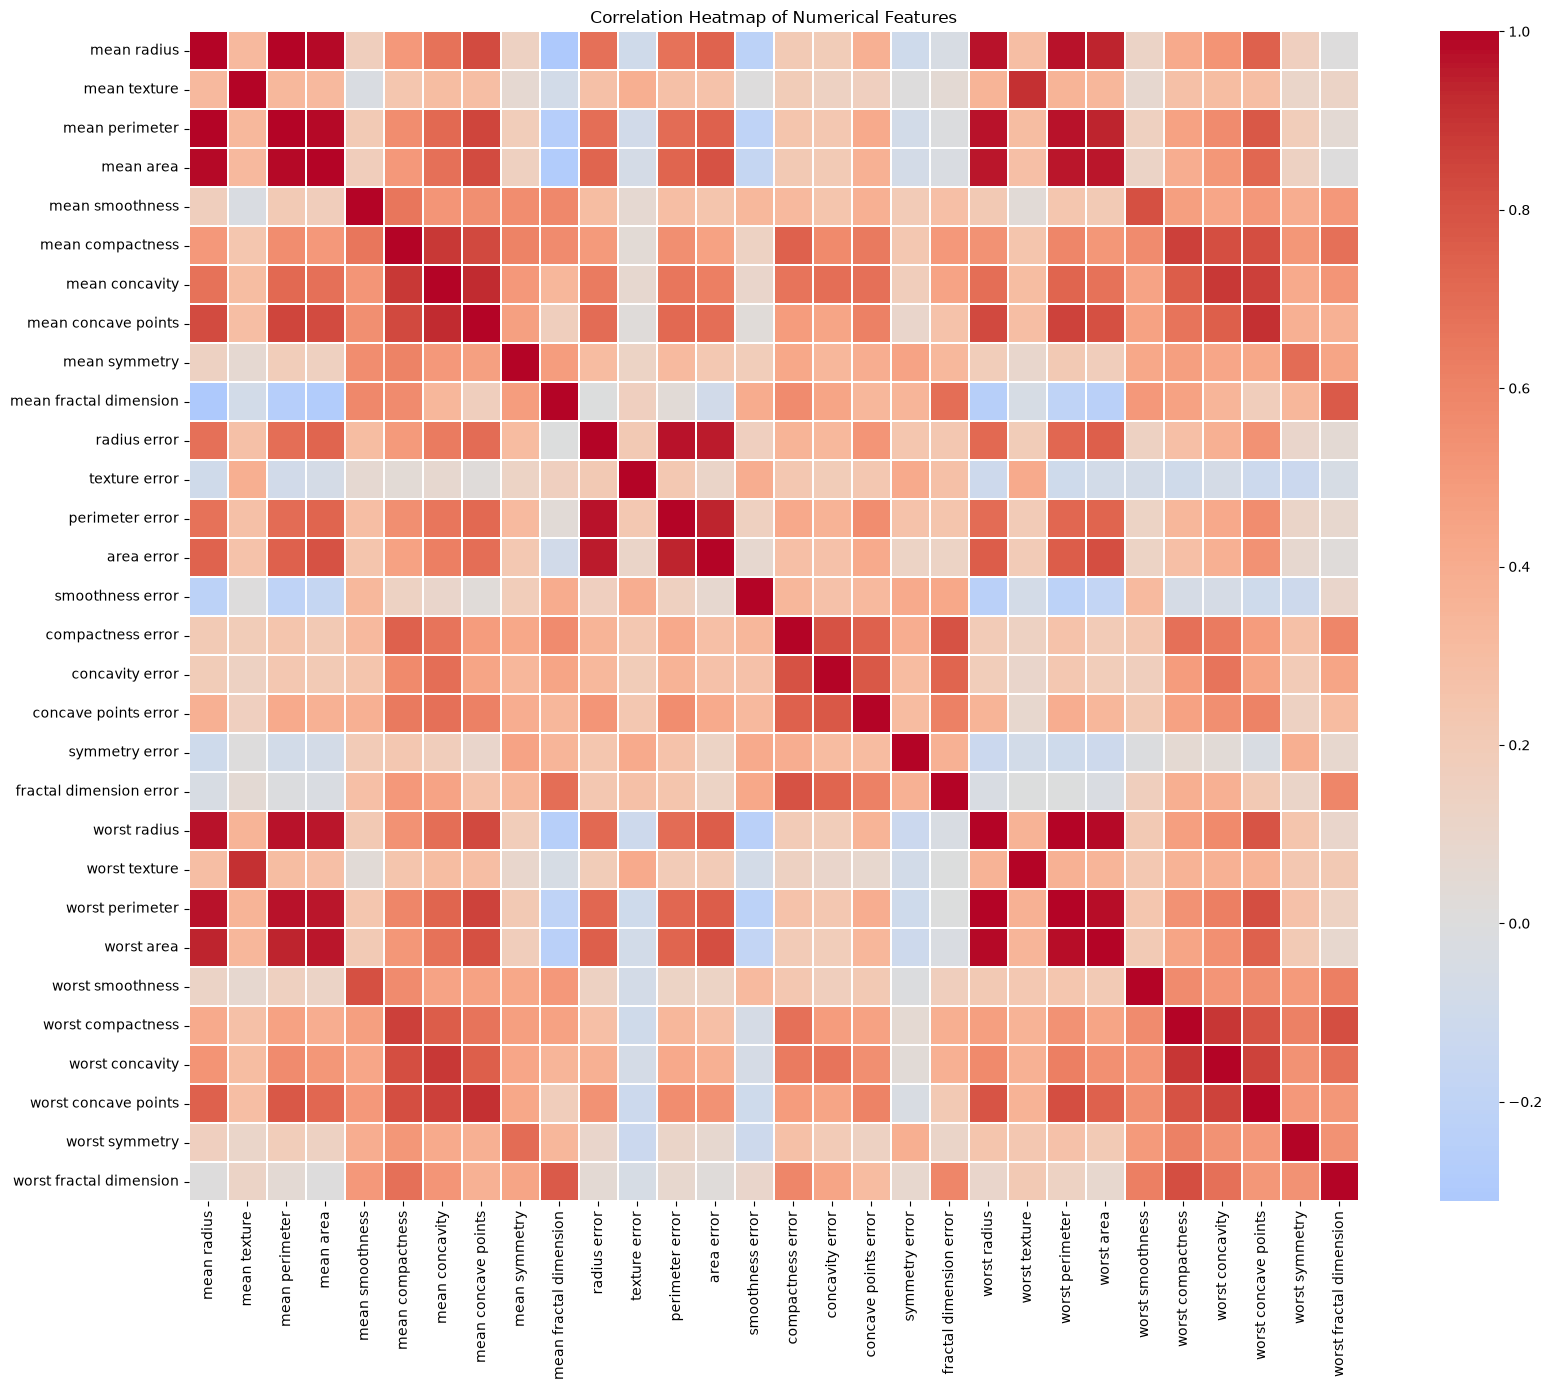

In [8]:
# Select numerical input features only
features = df.drop(columns=["diagnosis"])

# Calculate Pearson correlation matrix
correlation_matrix = features.corr()

# Plot correlation heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,
    square=True,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [9]:
# Calculate absolute feature correlations
corr_matrix = features.corr().abs()

# Select only the upper triangle to avoid duplicate pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify feature pairs with correlation greater than 0.90
high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_correlations = high_correlations[
    high_correlations["Correlation"] > 0.90
].sort_values(by="Correlation", ascending=False)

display(high_correlations.round(3))

,Feature 1,Feature 2,Correlation
2,mean radius,mean perimeter,0.998
622,worst radius,worst perimeter,0.994
3,mean radius,mean area,0.987
63,mean perimeter,mean area,0.987
623,worst radius,worst area,0.984
683,worst perimeter,worst area,0.978
312,radius error,perimeter error,0.973
82,mean perimeter,worst perimeter,0.970
20,mean radius,worst radius,0.970
80,mean perimeter,worst radius,0.969


# 3. Data Preprocessing

## 3.1 Separating Input Features and Target Variable

In [10]:
# Separate input features and target variable
X = df.drop(columns=["diagnosis"])

# Encode target: Malignant = 1, Benign = 0
y = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Input features shape: (569, 30)
Target variable shape: (569,)

Target distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


## 3.2 Splitting the Dataset into Training and Testing Sets

In [11]:

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training feature shape: (455, 30)
Testing feature shape: (114, 30)

Training target distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing target distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


# 4. Model Development

## 4.1 Defining Classification Models

Five classification algorithms are selected for this experiment.
Pipelines are used to combine preprocessing and model training
where feature scaling is required.

In [12]:


# Define five classification models
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=10000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", random_state=42))
    ])

}

# Display model names
print("Models selected for training:\n")

for model_name in models:
    print(model_name)

Models selected for training:

Logistic Regression
Decision Tree
KNN
Naive Bayes
SVM


## 4.2 Training Classification Models

In [13]:
# Train all five classification models

for model_name, model in models.items():

    print(f"Training {model_name}...")

    model.fit(X_train, y_train)

    print(f"{model_name} training completed.\n")

print("All five models have been trained successfully.")

Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training KNN...
KNN training completed.

Training Naive Bayes...
Naive Bayes training completed.

Training SVM...
SVM training completed.

All five models have been trained successfully.


## 4.3 Model Evaluation

The five trained classification models are evaluated using
the independent test dataset.

The evaluation metrics include Accuracy, AUC, Precision,
Recall, F1-score and Matthews Correlation Coefficient (MCC).

Malignant (1) is considered the positive class.

In [14]:


# Store evaluation results
results = []

# Evaluate each trained model
for model_name, model in models.items():

    # Predict class labels
    y_pred = model.predict(X_test)

    # Obtain prediction scores for AUC
    if model_name == "SVM":
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display results rounded to four decimal places
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


## 4.4 Confusion Matrix Analysis

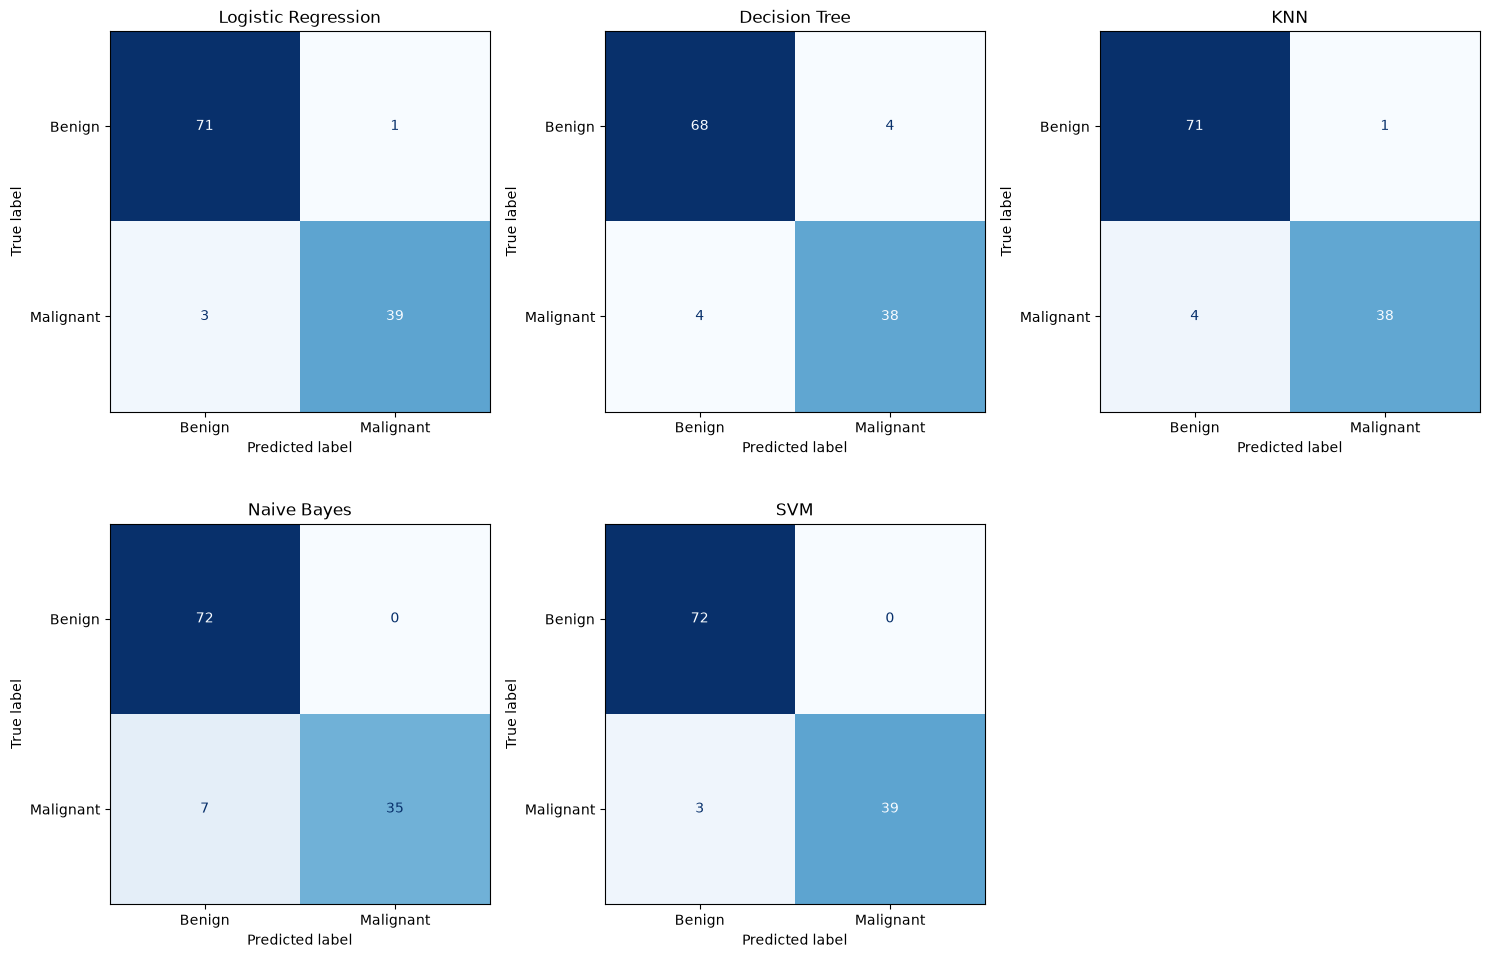

In [15]:
# Generate confusion matrices for all five models
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for i, (model_name, model) in enumerate(models.items()):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display confusion matrix
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    display_cm.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False
    )

    axes[i].set_title(model_name)

# Remove unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


In [16]:
# Create the model directory in the project root
model_dir = project_root / "model"
model_dir.mkdir(parents=True, exist_ok=True)

# Define model filenames
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

# Save all five trained models
for model_name, model in models.items():

    file_path = model_dir / model_files[model_name]

    joblib.dump(model, file_path)

    print(f"{model_name} saved successfully: {file_path}")

print("\nAll five models have been saved successfully.")

Logistic Regression saved successfully: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\model\logistic_regression.joblib
Decision Tree saved successfully: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\model\decision_tree.joblib
KNN saved successfully: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\model\knn.joblib
Naive Bayes saved successfully: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\model\naive_bayes.joblib
SVM saved successfully: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\model\svm.joblib

All five models have been saved successfully.


In [17]:
# Combine test features and target into one DataFrame
test_data = X_test.copy()

# Convert encoded target values back to original labels
test_data["diagnosis"] = y_test.map({
    0: "B",
    1: "M"
})

# Define the correct export path in the project root
test_file = project_root / "test_data.csv"

# Export test data to CSV
test_data.to_csv(test_file, index=False)

print("Test dataset exported successfully.")
print("File location:", test_file)
print("Shape:", test_data.shape)

print("\nTarget distribution:")
print(test_data["diagnosis"].value_counts())

Test dataset exported successfully.
File location: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\test_data.csv
Shape: (114, 31)

Target distribution:
diagnosis
B    72
M    42
Name: count, dtype: int64


In [18]:
from src.preprocessing import prepare_data
from src.train_models import create_models, train_models
from src.evaluate_models import evaluate_models

# Prepare the dataset
X, y = prepare_data(df)

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train all five models using the source file
trained_models = train_models(X_train, y_train)

# Evaluate all five models
source_results = evaluate_models(
    trained_models,
    X_test,
    y_test
)

display(source_results.round(4))

Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training KNN...
KNN training completed.

Training Naive Bayes...
Naive Bayes training completed.

Training SVM...
SVM training completed.



,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [19]:

# Create outputs directory in project root
output_dir = project_root / "outputs"
output_dir.mkdir(exist_ok=True)

# Save model comparison results
comparison_file = output_dir / "model_comparison.csv"

results_df.to_csv(comparison_file, index=False)

print("Model comparison results saved successfully.")
print("File location:", comparison_file)

Model comparison results saved successfully.
File location: l:\MTech\Machine_Learning\Assignment\Assignment_2_ML\outputs\model_comparison.csv


In [20]:
# Create confusion matrix output directory
cm_dir = project_root / "outputs" / "confusion_matrices"
cm_dir.mkdir(parents=True, exist_ok=True)

# Generate and save confusion matrices
for model_name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    fig, ax = plt.subplots(figsize=(6, 4))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

    # Create a filename
    file_name = model_name.lower().replace(" ", "_") + ".png"

    # Save image
    fig.savefig(
        cm_dir / file_name,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(f"{model_name} confusion matrix saved.")

print("\nAll confusion matrices saved successfully.")

Logistic Regression confusion matrix saved.
Decision Tree confusion matrix saved.
KNN confusion matrix saved.
Naive Bayes confusion matrix saved.
SVM confusion matrix saved.

All confusion matrices saved successfully.
